# `Задание 02. Сегментация изображений`

#### Фамилия, имя: 

Дата выдачи: <span style="color:red">__15 октября__</span>.

Дедлайн: <span style="color:red">__29 октября 23:59__</span>.

Стоимость: __10 баллов__ (основная часть заданий) + __4.25 балла__ (дополнительные задания).

<span style="color:red">__В ноутбуке все клетки должны выполняться без ошибок при последовательном их выполнении.__</span>

#### `Москва, 2025`

В этом задании вы будете решать задачу сегментации людей на фотографии с помощью нейросетевых архитектур `U-Net` и `LinkNet`. 

Данные для выполнения задания можно скачать по [ссылке](https://disk.yandex.ru/d/tI6d3LBMHTwOnw).

Везде, где требуется использование `wandb`, вы можете использовать незаблокированные аналоги.

## `Загрузка данных (1 балл)`

Для загрузки данных pytorch опирается на такую сущность, как **`Dataset`**.

Этот абстрактный класс определен в `torch.utils.data.dataset`:

```python
class Dataset(object):
    """An abstract class representing a Dataset.

    All other datasets should subclass it. All subclasses should override
    ``__len__``, that provides the size of the dataset, and ``__getitem__``,
    supporting integer indexing in range from 0 to len(self) exclusive.
    """

    def __getitem__(self, index):
        raise NotImplementedError

    def __len__(self):
        raise NotImplementedError

    def __add__(self, other):
        return ConcatDataset([self, other])
```
При определении нового источника данных мы создаем наследника данного класса и реализуем методы `__getitem__` и `__len__`.

Пример готового такого класса — `torchvision.datasets.ImageFolder`, который позволяет создать датасет на основе директории с ImageNet-подобной структурой поддиректорий (`./train/{class}` и `./val/{class}`):

```python
imagenet = torchvision.datasets.ImageFolder('path/to/imagenet_root/')
```

Реализуйте класс `PhotosDataset` для выданных данных.

**Внимание.** Возможно, стоит прочитать следующий пункт задания, чтобы реализация была удобной.

In [2]:
import os

import numpy as np
import numpy.testing as npt

import torch
from torch.utils.data import Dataset, DataLoader
from torchvision.models import vgg13, VGG13_Weights

import matplotlib_inline
import matplotlib.pyplot as plt

%matplotlib inline
matplotlib_inline.backend_inline.set_matplotlib_formats('pdf', 'svg')

In [3]:
from PIL import Image

class PhotosDataset(Dataset):
    def __init__(self, images_dir, target_dir=None, transforms=None):
        """
        Arguments
        ---------
        images_dir : str
            Path to directory with images
            
        target_dir : str
            Path to directory with masks.
            Each mask corresponds to one image.
            Corresponding mask and image have the same name, but different format.
            
        transforms : some collection
            Sequence of transformations for images and masks. 
        """
        self.images_dir = images_dir
        self.target_dir = target_dir
        self.transforms = transforms
        
        self.image_names = [file for file in os.listdir(images_dir)]

        if target_dir is not None:
            self.mask_names = []
            
            for img_name in self.image_names:
                pref = os.path.splitext(img_name)[0]
                mask_name = pref + '.png'
                mask_path = os.path.join(target_dir, mask_name)
                
                self.mask_names.append(mask_name)
        else:
            self.mask_names = None
        
    def __len__(self):
        return len(self.image_names)
                   
    def __getitem__(self, idx):
        """
        Arguments
        ---------
        idx : int
            Index of image and mask
        
        Returns
        -------
        (image, mask)
        """
        img_name = self.image_names[idx]
        img_path = os.path.join(self.images_dir, img_name)
        image = Image.open(img_path).convert('RGB')

        if self.mask_names is not None:
            mask_name = self.mask_names[idx]
            mask_path = os.path.join(self.target_dir, mask_name)
            mask = Image.open(mask_path).convert("L")
        else:
            mask = None

        if self.transforms is not None:
            image, mask = self.transforms(image, mask)

        return image, mask

In [77]:
DATA_PATH = '/kaggle/input/dl2-hw3-ds/people_data'

train_dataset_og = PhotosDataset(
    images_dir=os.path.join(DATA_PATH, 'train'),
    target_dir=os.path.join(DATA_PATH, 'train_mask'),
    transforms=None
)

In [25]:
train_dataset_og.__getitem__(0)

(<PIL.Image.Image image mode=RGB size=240x320>,
 <PIL.Image.Image image mode=L size=240x320>)

## `Модуль аугментации (2 балла)`

Конструктор стандартного `ImageFolder`, принимает параметр `transform` (и иногда `target_transform`).

Они служат для того, чтобы загружаемые изображения (обычно это `PIL.Image`) или таргеты преобразовывать в тензоры нужного вида.

В `torchvision` входит модуль `transforms` для стандартных примеров таких преобразований. В `transforms` могут содержаться случайные преобразования, это самый простой путь для реализации аугментации данных.

При определении кастомного трансформера помимо конструктора нужно реализовать лишь метод `__call__`:

```python
class HorizontalFlip(object):
    def __init__(self, mode=0):
        self.method = mode

    def __call__(self, img):
        """
        Args:
            img (PIL.Image): Image to be flipped.

        Returns:
            PIL.Image: Randomly flipped image.
        """
        if self.method:
            return img.transpose(Image.FLIP_LEFT_RIGHT)
        return img

```

С полным списком стандартных преобразований можно ознакомиться в [документации](https://pytorch.org/vision/0.12/transforms.html).

В данной части вам предлагается самостоятельно реализовать несколько кастомных трансформеров.
Обратите внимание, что для некоторых трансформеров, необходимо преобразовывать и изображение, и маску, а для каких-то только изображение.

Один из путей реализации:
* реализовать декоратор, делающий любое преобразование случайным
* реализовать декоратор, применяющий преобразование и к изображению, и к маске

Список трансформеров, которые надо реализовать:

1. случайное (с вероятностью $p$) горизонтальное отображение (flip) изображения 
2. случайное (с вероятностью $p$) вырезание фрагмента изображения (заданного или случайного размера)
3. случайное (с вероятностью $p$) изменение яркости изображения (на заданную или случайную величину)
4. случайное (с вероятностью $p$) изменение фона изображения (на изображение из заданного списка изображений)

Используйте разумные пределы для аугментаций. Одной из причин плохого обучения модели могут быть слишком сильные аугментации. Визуально убедитесь, что граничные случаи достаточно адекватны задаче.

Обратите внимание, что под вырезанием фрагмента подрузумевается вырезания части изображения из исходного, то есть вырезание какой-то части изображения (создание отверстий в изображении). Если после слоя вырезания размеры изображения поменялись, то вы неправильно реализовали модуль.

In [4]:
from PIL import ImageEnhance
import torchvision.transforms.functional as TF
import random

In [5]:
def show_image_raw(image, mask):
    fig, axes = plt.subplots(1, 2 if mask is not None else 1, figsize=(6, 4))

    if mask is None:
        axes = [axes]

    axes[0].imshow(image)
    axes[0].set_axis_off()
    axes[0].set_title('image')

    if mask is not None:
        axes[1].imshow(mask, cmap='gray')
        axes[1].set_axis_off()
        axes[1].set_title('mask')

    fig.tight_layout()
    plt.show()

Сразу будем демонстрировать корректную работу преобразований к следующему изображению:

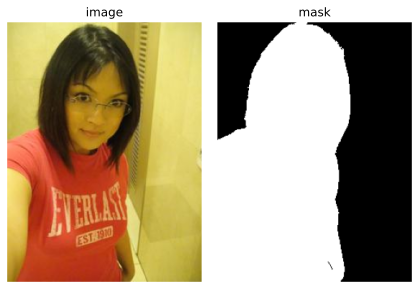

In [67]:
show_image_raw(train_dataset_og.__getitem__(0)[0], train_dataset_og.__getitem__(0)[1])

In [6]:
class RandomHorizontalFlip:
    def __init__(self, p=0.5):
        self.p = p

    def __call__(self, image, mask):
        if random.random() < self.p:
            image = image.transpose(Image.FLIP_LEFT_RIGHT)
            
            if mask is not None:
                mask = mask.transpose(Image.FLIP_LEFT_RIGHT)
                
        return image, mask

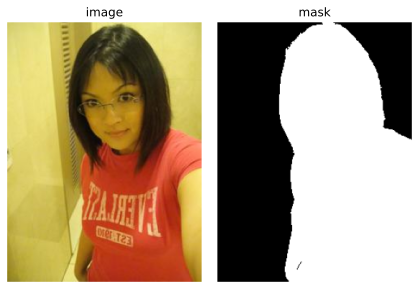

In [68]:
hf = RandomHorizontalFlip(p=1)
cp = hf.__call__(train_dataset_og.__getitem__(0)[0], train_dataset_og.__getitem__(0)[1])
show_image_raw(cp[0], cp[1])

In [7]:
class RandomCutout:
    def __init__(self, p=0.5, scale_range=(0.1, 0.5)):
        self.p = p
        self.scale_range = scale_range

    def __call__(self, image, mask):
        if random.random() >= self.p:
            return image, mask

        img_np = np.array(image).copy()
        h, w, _ = img_np.shape

        min_scale, max_scale = self.scale_range
        hl_h = int(random.uniform(min_scale, max_scale) * h)
        hl_w = int(random.uniform(min_scale, max_scale) * w)

        hl_h = max(1, min(hl_h, h))
        hl_w = max(1, min(hl_w, w))

        c_y = random.randint(0, h - 1)
        c_x = random.randint(0, w - 1)

        y_1 = max(0, c_y - hl_h // 2)
        y_2 = min(h, y_1 + hl_h)
        x_1 = max(0, c_x - hl_w // 2)
        x_2 = min(w, x_1 + hl_w)

        img_np[y_1:y_2, x_1:x_2, :] = 0

        image = Image.fromarray(img_np.astype(np.uint8))

        return image, mask

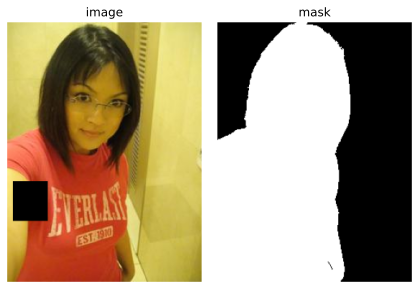

In [69]:
rc = RandomCutout(p=1)
cp = rc.__call__(train_dataset_og.__getitem__(0)[0], train_dataset_og.__getitem__(0)[1])
show_image_raw(cp[0], cp[1])

In [8]:
class RandomBrightness:
    def __init__(self, p=0.5, brightness_range=(0.5, 1.3)):
        self.p = p
        self.brightness_range = brightness_range

    def __call__(self, image, mask):
        if random.random() < self.p:
            factor = random.uniform(self.brightness_range[0], self.brightness_range[1])
            enhancer = ImageEnhance.Brightness(image)
            image = enhancer.enhance(factor)
            
        return image, mask

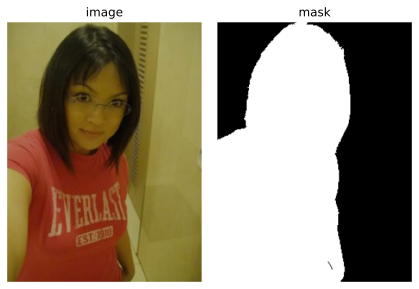

In [70]:
rb = RandomBrightness(p=1)
cp = rb.__call__(train_dataset_og.__getitem__(0)[0], train_dataset_og.__getitem__(0)[1])
show_image_raw(cp[0], cp[1])

In [9]:
class RandomBackgroundReplace:
    def __init__(self, p=0.5, background_images=None):
        self.p = p
        self.backgrounds = []

        if background_images is None:
            background_images = []

        for bg in background_images:
            self.backgrounds.append(bg.convert('RGB'))

    def __call__(self, image, mask):
        if (mask is None) or (len(self.backgrounds) == 0):
            return image, mask

        if random.random() >= self.p:
            return image, mask

        bg = random.choice(self.backgrounds)

        w, h = image.size
        bg = bg.resize((w, h), resample=Image.BILINEAR)

        img_np = np.array(image).astype(np.uint8)
        bg_np  = np.array(bg).astype(np.uint8)
        mask_np = np.array(mask).astype(np.uint8)

        person = (mask_np > 0).astype(np.uint8)
        person = np.expand_dims(person, axis=-1)

        out_np = img_np * person + bg_np * (1 - person)

        image = Image.fromarray(out_np.astype(np.uint8))

        return image, mask

Изображение фона:

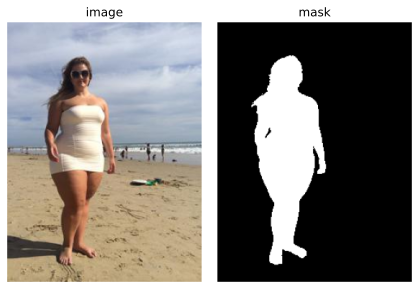

In [71]:
show_image_raw(train_dataset_og.__getitem__(1)[0], train_dataset_og.__getitem__(1)[1])

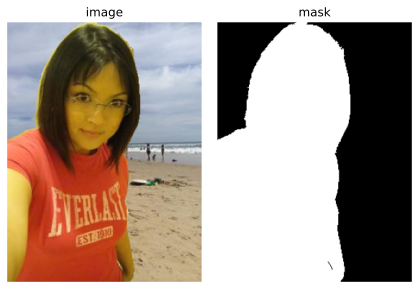

In [72]:
rbr = RandomBackgroundReplace(p=1, background_images=[train_dataset_og.__getitem__(1)[0]])
cp = rbr.__call__(train_dataset_og.__getitem__(0)[0], train_dataset_og.__getitem__(0)[1])
show_image_raw(cp[0], cp[1])

In [10]:
class Compose:
    def __init__(self, transforms_list):
        self.transforms = transforms_list

    def __call__(self, image, mask):
        for trn in self.transforms:
            image, mask = trn(image, mask)
        return image, mask

Добавьте случайные преобразования в ваши датасеты. Также, добавьте преобразование в tensor и нормализацию для изображения:

```python
transforms.ToTensor()
transforms.Normalize(
    mean=[0.485, 0.456, 0.406],
    std=[0.229, 0.224, 0.225]
)
```

In [11]:
class ToTensorAndNormalize:
    def __init__(self):
        self.mean = [0.485, 0.456, 0.406]
        self.std = [0.229, 0.224, 0.225]

    def __call__(self, image, mask):
        image = TF.to_tensor(image)
        image = TF.normalize(image, mean=self.mean, std=self.std)

        if mask is not None:
            mask_np = np.array(mask, dtype=np.uint8)
            mask_bin = (mask_np > 0).astype(np.float32)
            mask = torch.from_numpy(mask_bin).unsqueeze(0)

        return image, mask

In [13]:
train_images_dir = '/kaggle/input/dl2-hw3-ds/people_data/train'

background_imgs = []
for img in os.listdir(train_images_dir):
    img_path = os.path.join(train_images_dir, img)
    bg_img = Image.open(img_path).convert('RGB')
    background_imgs.append(bg_img)

In [14]:
transforms = Compose([
    RandomHorizontalFlip(),
    RandomCutout(),
    RandomBrightness(),
    RandomBackgroundReplace(p=0.3, background_images=background_imgs),
    ToTensorAndNormalize()
])

In [15]:
DATA_PATH = '/kaggle/input/dl2-hw3-ds/people_data'

train_dataset = PhotosDataset(
    images_dir=os.path.join(DATA_PATH, 'train'),
    target_dir=os.path.join(DATA_PATH, 'train_mask'),
    transforms=transforms
)

test_dataset = PhotosDataset(
    images_dir=os.path.join(DATA_PATH, 'test'),
    target_dir=os.path.join(DATA_PATH, 'test_mask'),
    transforms=None
)

Функция для отображения изображения:

In [16]:
def show_idx_image(dataset, idx):
    image, mask = dataset[idx]

    image = image.permute(1, 2, 0).numpy()
    image = (image * np.array([0.229, 0.224, 0.225])) + np.array([0.485, 0.456, 0.406])
    image = np.clip(image, 0, 1)

    mask = mask.squeeze(0).numpy()

    fig, axes = plt.subplots(1, 2, figsize=(6, 4))

    axes[0].imshow(image)
    axes[1].imshow(mask, cmap='gray')
    
    axes[0].set_axis_off()
    axes[1].set_axis_off()
    
    fig.tight_layout()
    plt.show()

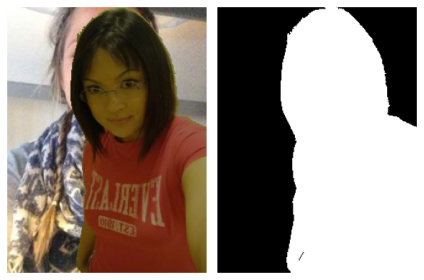

In [106]:
show_idx_image(train_dataset, 0)

Отобразите несколько изображений и масок, на которых будет видна правильная работа вашего модуля аугментации данных. Необходимо проверить каждый модуль аугментации отдельно, в ином случае будут сниматься баллы.

**Важно:** Проверьте корректность работы модулей, действительно ли маска изображения корректна для изображения после аугментации.

Проверили все выше

## `Загрузчики`

При обучении сети удобнее работать не с датасетами, а с загрузчиками. Загрузчики создаются на основе датасета и позволяют итерироваться по батчам из него.

Обратите внимание на параметры `DataLoader`. При `num_workers`$\;> 1$, батчи готовятся (загружаются картинки, обрабатываются и так далее) сразу в нескольких фоновых процессах. С помощью параметра `shuffle` можно подавать картинки на обучение в случайном порядке.

Обычно, скорость обработки данных на GPU превышает скорость загрузки данных в одном процессе, поэтому типичное значение для `num_workers`$\approx 3\text{-}10$. 

Учтите, что на некоторых системах в Jupyter Notebook при `num_workers`$>0$ `DataLoader` перестаёт работать. В таком случае установите это значение в $0$.

In [17]:
test_data_loader = DataLoader(test_dataset, batch_size=8, num_workers=3)
train_data_loader = DataLoader(train_dataset, batch_size=8, num_workers=3, shuffle=True)

## `DiceLoss (1 балл)`

Функция потерь реализовывается как и все стандартные нейронные модули в pytorch, через `torch.nn.Module`. В ячейке ниже вам предлагается реализовать функцию потерь `dice` (аналог меры Жаккарда).

Результат **Dice Loss** определим как:

$$
\text{Dice Coefficient} = 2\frac{|A \cap B| }{|A| + |B|} \leadsto \text{Dice Loss} = 1 - \frac{2\sum\limits_{i, j}a_{ij}b_{ij}}{\sum\limits_{ij}(a_{ij} + b_{ij} + \varepsilon)}
$$

где $a_{ij} \in [0, 1]$ — предсказанная вероятность нахождения человека в пикселе изображения, $b_{ij}$ — истинная разметка для пикселя изображения.

In [18]:
class DiceLoss(torch.nn.Module):
    def __init__(self, eps=1e-7, reduction=None, with_logits=True):
        """
        Arguments
        ---------
        eps : float
            eps in denominator
        reduction : Optional[str] (None, 'mean' or 'sum')
            specifies the reduction to apply to the output:
            
            None: no reduction will be applied
            'mean': the sum of the output will be divided by the number of elements in the batch
            'sum':  the output will be summed. 
        with_logits : bool
            If True, use additional sigmoid for inputs
        """
        super().__init__()
        self.eps = eps
        self.reduction = reduction
        self.with_logits = with_logits
        
    def forward(self, logits, true_labels):
        """
        Arguments
        ---------
        logits: torch.Tensor
            Unnormalized probability of true class. Shape: [B, ...]
        true_labels: torch.Tensor
            Mask of correct predictions. Shape: [B, ...]
        Returns
        -------
        torch.Tensor
            If reduction is 'mean' or 'sum' returns a tensor with a single element
            Otherwise, returns a tensor of shape [B]
        """
        true_labels = true_labels.to(torch.long).float()
        
        if self.with_logits:
            probs = torch.sigmoid(logits)
        else:
            probs = logits

        dims = tuple(range(1, probs.dim()))

        intrs = (probs * true_labels).sum(dim=dims)
        dnm = (probs.sum(dim=dims) + true_labels.sum(dim=dims) + self.eps)

        dice_score = (2 * intrs) / dnm
        loss_per_sample = 1 - dice_score  
        
        if self.reduction == 'sum':
            loss_value = loss_per_sample.sum()
        elif self.reduction == 'mean':
            loss_value = loss_per_sample.mean()
        elif self.reduction is None:
            loss_value = loss_per_sample
            
        return loss_value

Проверка реализации:

In [120]:
logits = torch.tensor([
    [[0, 0.5], [0.5, 1]],
    [[0.1, 0.1], [0, 0]],
])

target = torch.tensor([
    [[0, 1], [1, 1]],
    [[1, 0], [0, 1]],
])

losses = DiceLoss(with_logits=False, reduction=None, eps=1e-7)(logits, target)
npt.assert_almost_equal(losses.numpy(), np.array([0.2, 0.90909]), decimal=4)

loss = DiceLoss(with_logits=False, reduction='mean', eps=1e-7)(logits, target)
npt.assert_almost_equal(float(loss.numpy()), 0.554545, decimal=4)

loss = DiceLoss(with_logits=False, reduction='sum', eps=1e-7)(logits, target)
npt.assert_almost_equal(float(loss.numpy()), 1.10909, decimal=4)

## `U-Net (3 балла)`

Для решения задачи сегментации будем использовать [U-Net](https://arxiv.org/pdf/1505.04597.pdf) с энкодером из первых блоков предобученного `VGG13`.

Концептуальная схема представлена на диаграмме ниже:

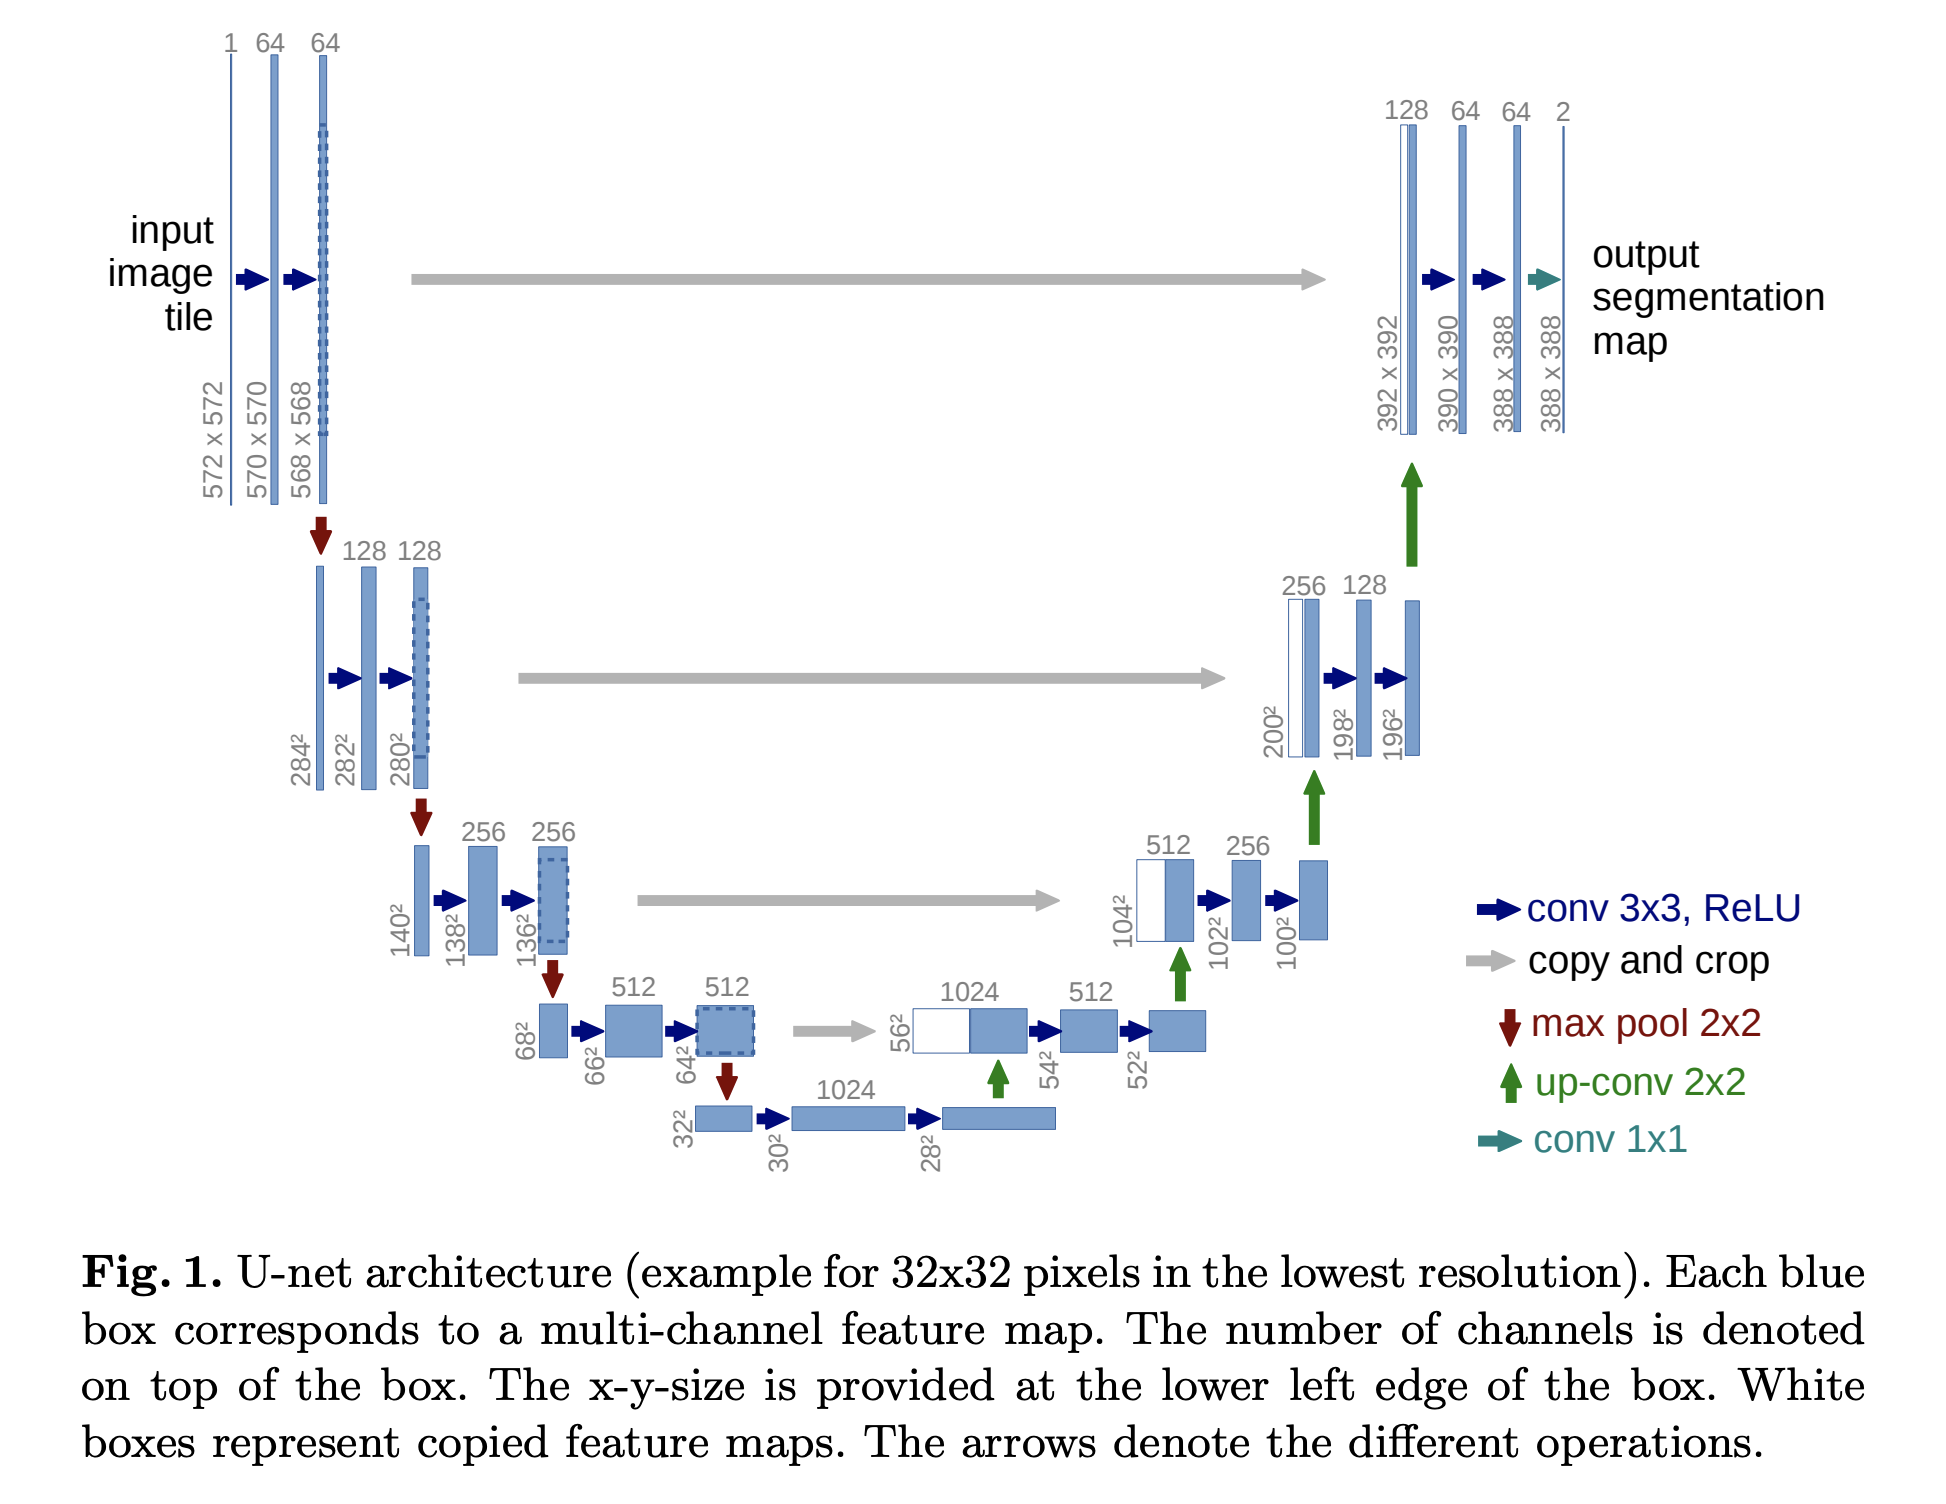

Заметим, что блоки VGG13 имеют следующий вид:
```python
    (0): Conv2d(...)
    (1): ReLU(...)
    (2): Conv2d(...)
    (3): ReLU(...)
    (4): MaxPool2d(...)
```

Для удобства, уберём слои `MaxPool2d` из блоков энкодера и будем применять pooling отдельно. Возможно, вам будет полезно вывести архитектуру модели `VGG` и изучить параметры слоев pooling.

При реализации `Decoder` вам пригодится интерполяция, для этого можно использовать `torch.nn.functional.interpolate` с `mode=nearest`. 

Реализуйте архитектуру данной сети.

#### `Encoder`

In [19]:
import torch.nn as nn
import torch.nn.functional as F

class VGG13Encoder(torch.nn.Module):
    def __init__(self, num_blocks, weights=VGG13_Weights.DEFAULT):
        super().__init__()
        self.num_blocks = num_blocks
        
        # Будем использовать предобученную VGG13 в качестве backbone
        feature_extractor = vgg13(weights=weights).features
        
        # Каждый блок энкодера U-Net — это блок VGG13 без MaxPool2d
        self.blocks = torch.nn.ModuleList()
        for idx in range(self.num_blocks):
            # Возьмите нужные слои из `feature_extractor` для очередного U-Net блока
            # Объедините их с помощью `torch.nn.Sequential`
            start = idx * 5
            end = start + 4
            block_layers = []
            
            for layer_i in range(start, end):
                block_layers.append(feature_extractor[layer_i])
                
            self.blocks.append(nn.Sequential(*block_layers))

    def forward(self, x):
        activations = []
        out = x
        for idx, block in enumerate(self.blocks):
            # Примените очередной блок U-Net
            out = block(out)

            # Сохраните активации для передачи их в декодер
            activations.append(out)

            # При необходимости примените max-pool
            # Можно использовать `torch.functional.F.max_pool2d`
            if idx != self.num_blocks - 1:
                out = F.max_pool2d(out, kernel_size=2, stride=2)
            
        return activations

In [114]:
assert sum((param.numel() for param in VGG13Encoder(num_blocks=1).parameters())) == 38720
assert sum((param.numel() for param in VGG13Encoder(num_blocks=2).parameters())) == 260160
assert sum((param.numel() for param in VGG13Encoder(num_blocks=3).parameters())) == 1145408

x = torch.arange(1 * 3 * 320 * 240).reshape(1, 3, 320, 240) / (1 * 3 * 320 * 240)
out = VGG13Encoder(num_blocks=3)(x)

assert len(out) == 3
npt.assert_almost_equal(torch.linalg.norm(out[0]).item(), 902.218, decimal=3)
npt.assert_almost_equal(torch.linalg.norm(out[1]).item(), 571.030, decimal=3)
npt.assert_almost_equal(torch.linalg.norm(out[2]).item(), 648.068, decimal=3)

#### `Decoder`

In [20]:
class DecoderBlock(torch.nn.Module):
    def __init__(self, out_channels):
        super().__init__()

        self.upconv = torch.nn.Conv2d(
            in_channels=out_channels * 2, out_channels=out_channels,
            kernel_size=3, padding=1, dilation=1
        )
        self.conv1 = torch.nn.Conv2d(
            in_channels=out_channels * 2, out_channels=out_channels,
            kernel_size=3, padding=1, dilation=1
        )
        self.conv2 = torch.nn.Conv2d(
            in_channels=out_channels, out_channels=out_channels,
            kernel_size=3, padding=1, dilation=1
        )
        self.relu = torch.nn.ReLU()
        
    def forward(self, down, left):
        # Upsample x2 и свёртка
        x = F.interpolate(down, scale_factor=2, mode='nearest')
        x = self.upconv(x)
        
        # Конкатенация выхода энкодера и предыдущего блока декодера
        x = torch.cat([x, left], dim=1)
        
        # Две свёртки с ReLu
        x = self.relu(self.conv1(x))
        x = self.relu(self.conv2(x))

        return x

In [21]:
class Decoder(torch.nn.Module):
    def __init__(self, num_filters, num_blocks):
        super().__init__()

        self.blocks = torch.nn.ModuleList()
        for idx in range(num_blocks):
            self.blocks.insert(0, DecoderBlock(num_filters * 2 ** idx))

    def forward(self, acts):
        up = acts[-1]
        for block, left in zip(self.blocks, acts[-2::-1]):
            up = block(up, left)
        return up

#### `U-Net`

In [22]:
class UNet(torch.nn.Module):
    def __init__(self, num_classes=1, num_blocks=4):
        super().__init__()
        
        self.encoder = VGG13Encoder(num_blocks=num_blocks)
        
        self.decoder = Decoder(num_filters=64, num_blocks=num_blocks - 1)
        
        # Свёртка 1x1 для попиксельной агрегации каналов
        self.final = nn.Conv2d(in_channels=64, out_channels=num_classes, kernel_size=1, padding=0)

    def forward(self, x):
        actvs = self.encoder(x)

        x = self.decoder(actvs)

        x = self.final(x)

        return x

In [53]:
model = UNet(num_classes=1, num_blocks=3)
x = torch.arange(1 * 3 * 320 * 240).reshape(1, 3, 320, 240) / (1 * 3 * 320 * 240)

assert sum((param.numel() for param in model.parameters())) == 2067649
assert list(model(x).shape) == [1, 1, 320, 240]
model

UNet(
  (encoder): VGG13Encoder(
    (blocks): ModuleList(
      (0): Sequential(
        (0): Conv2d(3, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
        (1): ReLU(inplace=True)
        (2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
        (3): ReLU(inplace=True)
      )
      (1): Sequential(
        (0): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
        (1): ReLU(inplace=True)
        (2): Conv2d(128, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
        (3): ReLU(inplace=True)
      )
      (2): Sequential(
        (0): Conv2d(128, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
        (1): ReLU(inplace=True)
        (2): Conv2d(256, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
        (3): ReLU(inplace=True)
      )
    )
  )
  (decoder): Decoder(
    (blocks): ModuleList(
      (0): DecoderBlock(
        (upconv): Conv2d(256, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
       

### `Оценивание качества сети`


Обычно, оптимизируемый функционал сложно интерпретировать, а так же в разных экспериментах могут использоваться разные функции потерь. Поэтому необходимо замерять и отслеживать независимую метрику качества. Предлагается использовать **IoU (Intersection over Union)** — один из стандартных вариантов для задачи сегментации:
$$
\text{IoU} = \frac{|A \cap B|}{|A \cup B|} = \frac{\sum\limits_{ij}a_{ij}b_{ij}}{\sum\limits_{ij}a_{ij} + b_{ij} - a_{ij}b_{ij}}
$$

Учтите, что знаменатель может быть равен нулю, например, если маска нулевая. Такие объекты можно не учитывать при агрегации и пропускать, так как в ином случае подсчет метрики на всем батче будет NaN. В pytorch есть встроенные для этого функции с префиксом nan.


In [24]:
class IoUScore(torch.nn.Module):
    def __init__(self, threshold, reduction=None):
        """
        Arguments
        ---------
        threshold : float
            threshold for logits binarization
        reduction : Optional[str] (None, 'mean' or 'sum')
            specifies the reduction to apply to the output:
            
            None: no reduction will be applied
            'mean': the sum of the output will be divided by the number of elements in the batch
            'sum':  the output will be summed. 
        with_logits : bool
            If True, use additional sigmoid for inputs
        """
        super().__init__()
        
        self.threshold = threshold
        self.reduction = reduction
        
    @torch.no_grad()
    def forward(self, logits, true_labels):
        """
        Arguments
        ---------
        logits: torch.Tensor
            Unnormalized probability of true class. Shape: [B, ...]
        true_labels: torch.Tensor
            Mask of correct predictions. Shape: [B, ...]
        Returns
        -------
        torch.Tensor
            If reduction is 'mean' or 'sum' returns a tensor with a single element
            Otherwise, returns a tensor of shape [B]
        """
        true_labels = true_labels.to(torch.long).float()

        pred_mask = (logits > self.threshold).to(torch.float32)

        dims = tuple(range(1, pred_mask.dim()))

        intrs = (pred_mask * true_labels).sum(dim=dims)
        un = pred_mask.sum(dim=dims) + true_labels.sum(dim=dims) - intrs

        iou_ps = intrs / un
        iou_ps = torch.where(un > 0, iou_ps, torch.full_like(iou_ps, float('nan')))
        
        if self.reduction == 'sum':
            score = torch.nansum(iou_ps) 
        elif self.reduction == 'mean':
            score = torch.nanmean(iou_ps)
        else:
            score = iou_ps
            
        return score

In [136]:
logits = torch.tensor([
    [
        [0.3089,  0.4311, -0.9711],
        [0.9030,  1.0325, -0.7607],
        [0.9648, -0.5528, -1.1010]
    ], [
        [0.8906,  0.8099,  0.4458],
        [2.6215, -1.3198,  0.3142],
        [0.2262, -0.9175, -0.0174]
    ], [
        [0.8906,  0.8099,  0.4458],
        [2.6215, -1.3198,  0.3142],
        [0.2262, -0.9175, -0.0174]
    ]
])
true_labels = torch.tensor([
    [
        [0., 1., 0.],
        [1., 0., 0.],
        [0., 0., 1.]
    ], [
        [1., 1., 1.],
        [1., 0., 1.],
        [1., 0., 0.]
    ], [
        [1., 1., 1.],
        [0., 1., 1.],
        [1., 1., 1.]
    ]
])

scores = IoUScore(0.0)(logits, true_labels)
npt.assert_almost_equal(scores.numpy(), np.array([0.3333, 1.0000, 0.5556]), decimal=4)

score = IoUScore(0.0, reduction='sum')(logits, true_labels)
npt.assert_almost_equal(score.item(), 1.8889, decimal=4)

score = IoUScore(0.0, reduction='mean')(logits, true_labels)
npt.assert_almost_equal(score.item(), 0.6296, decimal=4)

### `Логирование`

При реализации цикла обучения необходимо сохранять метрики $1\text{-}9$ с использованием модуля [torch.utils.tensorboard](https://pytorch.org/docs/stable/tensorboard.html) или с помощью модуля [wandb](https://docs.wandb.ai/tutorials/) вам предлагается самим выбрать более удобный для вас модуль.

Для отслеживания процесса обучения обычно требуется сохранять информацию разных его аспектах.

Для полного контроля над процессом обучения обычно требуется сохранять информацию о разных статистиках. Самыми очевидными являются:
1. Значение функции потерь (лосса) на обучающей и тестовой выборках
2. Метики качества, например, **Dice Coefficient** и **IoU (Intersection over Union)** на обучающей и тестовой выборках

Однако, суррогатные метрики могут не отражать реального качества. Поэтому для моделей, которые выдают визуализируемый результат, обычно логируют предсказания для некоторых объектов выборки. В задаче сегментации естественным вариантом является логирование четвёрки: исходное изображение, истинная маска, маска вероятностей истинного класса, бинаризованная маска. 

*Замечание:* лосс и качество на обучающей выборке обычно логируют не только в конце каждой эпохи, но и по отдельным батчам на каждой итерации.

3. Чтобы отслеживать динамику обучения необходимо зафиксировать небольшой набор объектов обучающей и тестовой выборок и после каждой эпохи обучения логировать указанные четыре картинки для каждого объекта.

*Замечание:* можно логировать четвёрки изображений независимо, однако, удобнее объединить их на одной фигуре [реализация через Tensorboard](https://pytorch.org/docs/stable/tensorboard.html#torch.utils.tensorboard.writer.SummaryWriter.add_figure), [реализация через Wandb](https://docs.wandb.ai/guides/track/log/plots/#matplotlib-and-plotly-plots) (лучше делать через fig и Image). Дополнительный плюс — возможность подписать значения метрик для этого объекта в заголовке изображения или добавить colorbar для более простой интерпретации предсказанной маски.

Для удобной категоризации экспериментов обычно в начале обучения сохраняют:

4. Гиперпараметры модели [реализация через Tensorboard](https://pytorch.org/docs/stable/tensorboard.html#torch.utils.tensorboard.writer.SummaryWriter.add_hparams), [реализация через Wandb](https://docs.wandb.ai/guides/track/config/)
5. Структуру модели [реализация через Tensorboard](https://pytorch.org/docs/stable/tensorboard.html#torch.utils.tensorboard.writer.SummaryWriter.add_graph), **про реализацию wandb ниже**

Для исследования технических особенностей обучения полезно логировать следующие статистики:

6. Распределение весов, активаций, градиентов [реализация через Tensorboard](https://pytorch.org/docs/stable/tensorboard.html#torch.utils.tensorboard.writer.SummaryWriter.add_histogram), [реализация через Wandb](https://docs.wandb.ai/ref/python/data-types/histogram/). Сохранять гистограммы каждого параметра после каждой итерации может быть вычислительно неэффективно, поэтому обычно сохраняют распределения весов для каждого отдельного слоя нейронной сети после каждой эпохи. 
7. Норма весов и норма градиента на каждой итерации

Наконец, после каждой эпохи можно визуализировать промежуточные представления входных данных:

8. Активации после каждого слоя/блока, как изображения
9. Градиенты функции потерь по активациям для некоторых объектов обучающей выборки, как изображения

*Замечание:* для реализации пунктов 8, 9 менять код модели не требуется. Используйте хуки: [register_full_backward_hook](https://pytorch.org/docs/stable/generated/torch.nn.Module.html#torch.nn.Module.register_full_backward_hook) (данный хук не работает с inplace операциями, например, с `torch.nn.ReLU(inplace=True)`. Или не используйте inplace операции, или используйте [`Tensor.register_hook`](https://github.com/pytorch/pytorch/issues/61519)), [register_forward_hook](https://pytorch.org/docs/stable/generated/torch.nn.Module.html#torch.nn.Module.register_forward_hook).

Файлы с логами, а также чекпоинты весов модели после итерации с наилучшим валидационным качеством (смотрите [torch.save](https://pytorch.org/docs/stable/generated/torch.save.html) и [torch.nn.Module.state_dict](https://pytorch.org/tutorials/recipes/recipes/what_is_state_dict.html)) для **ВСЕХ** проведённых экспериментов (за исключением упавших, недосчитанных и так далее) необходимо сдать в anytask.

#### `Некоторые советы по wandb`

- При логировании всегда указывайте параметр step, который должен не уменьшаться.

- При логировании изображений лучше их нормировать в диапазон [0, 1] как в функции `show_idx_image` выше. Для логирования предсказаний маски, лучше использовать вероятности. При неправильном диапозоне изображения могут отображаться неверно!

- Вместо логирования изображений, лучше логировать `matplotlib` графики и соответсвующие им `figure`. Кроме того, лучше закрывать все открытые графики, чтобы не перегружать ноутбук. Пример кода:


```python
fig, ax = plt.subplots(...)
...
wandb.log({key: wandb.Image(fig)}, step=global_step)
plt.close('all')
```

- Функционал построение bins в `wandb.Histogram` ограничен, можете посмотреть в сторону аргумента `np_histogram`.

- Wandb не имеет широкого функционала для логирования структуры модели. Есть способ через wandb.watch(net, log_graph=True), но получаемый результаты сильно отличаются от возможностей `tensorboard`. К счастью, `wandb` умеет синхронизировать логи с `Tensorboard` поэтому можно использовать следующую логику:


```python
wandb.init(
    project=project_name, 
    name=run_name, 
    config=config, 
    sync_tensorboard=True        # Синхронизация с tensorboard
)

writer = SummaryWriter(run_name) # Создание логера tensorboard

# Логирование графа модели
writer.add_graph(net, input_x)
writer.close()

train_loop(...)
wandb.finish()
```

- `wandb` по умолчанию сохраняет все логи локально и на сайте в вашем личном хранилище. В случае перезагрузки `Google Colab` локальные файлы не сохраняются! Кроме того, скачивание файлов не через GoogleDisk достаточно продолжительное (в районе 20-30 минут).

- В `wandb` можно легко сохранять код и указать директорию, так вы никогда не забудете какой именно код получает результаты логов.

```python
wandb.init(..., settings=wandb.Settings(code_dir="."))
```

Кроме того, можно сохранить отдельные файлы:

```python
wandb.init(..., save_code=True)
wandb.run.log_code(
    "./", 
    include_fn=lambda path: condition(path)
)
```

- В `wandb` есть функция для автоматического логирования весов и градиентов модели `wandb.watch()`, но функционал слишком ограничен и накладывает слишком много накладных расходов. **Лучше писать руками!**

#### `Некоторые советы по tensorboard`

- Функционал и возможности `tensorboard` шире (работа с 3D, продвинутые визуализации).

- `tensorboard` сохраняет логи только локально, то есть после закрытия `Google Colab` ничего не сохранится. В реальных проектах это является сильной стороной, так как гарантирует безопасность и конфиденциальность.

- Для визуализации логов достаточно запустить в ноутбуке или в терминале соответсвующее расширение, однако в случае `Google Colab` для этого приходится прокидывать порты, [подробнее тут](https://stackoverflow.com/questions/47818822/can-i-use-tensorboard-with-google-colab).

- `tensorboard` меньше лагает и более легковесный.


### `Некоторые советы по логированию`

- Вы можете выбрать либо `wandb`, либо `tensorboard`.

- В реальных проектах лучше добавить логирование кода с целью сохранения и воспроизводимости результатов.

- Называйте запуски осмысленно, чтобы по названию можно было понять смысл запуска и варьеруемые параметры.


In [ ]:
from torch.utils.tensorboard import SummaryWriter
import matplotlib.pyplot as plt

In [ ]:
%load_ext tensorboard
%tensorboard --logdir ./runs

Подготовим обучающий, валидационный и тестовый датасеты

In [66]:
train_transforms = Compose([
    RandomHorizontalFlip(),
    RandomCutout(),
    RandomBrightness(),
    RandomBackgroundReplace(background_images=background_imgs),
    ToTensorAndNormalize()
])

val_transforms = Compose([
    ToTensorAndNormalize()
])

In [67]:
DATA_PATH = '/kaggle/input/dl2-hw3-ds/people_data'

full_train_aug = PhotosDataset(
    images_dir=os.path.join(DATA_PATH, 'train'),
    target_dir=os.path.join(DATA_PATH, 'train_mask'),
    transforms=train_transforms
)

full_train_clean = PhotosDataset(
    images_dir=os.path.join(DATA_PATH, 'train'),
    target_dir=os.path.join(DATA_PATH, 'train_mask'),
    transforms=val_transforms
)

test_dataset = PhotosDataset(
    images_dir=os.path.join(DATA_PATH, 'test'),
    target_dir=os.path.join(DATA_PATH, 'test_mask'),
    transforms=val_transforms
)

In [68]:
from sklearn.model_selection import train_test_split
from torch.utils.data import Subset

num_total = len(full_train_aug)
all_indices = np.arange(num_total)

train_idx, val_idx = train_test_split(all_indices, test_size=0.2, random_state=42, shuffle=True)

train_dataset = Subset(full_train_aug, train_idx)
val_dataset = Subset(full_train_clean, val_idx)

In [69]:
from torch.utils.data import DataLoader

train_data_loader = DataLoader(train_dataset, batch_size=8, num_workers=3, shuffle=True)

val_data_loader = DataLoader(val_dataset, batch_size=8, num_workers=3, shuffle=False)

Создадим отдельную "валидационную" выборку из картинок, по которым будем отслеживать работу модели по эпохам - смотреть на 4 вида их представления

In [70]:
train_vis_indices = train_idx[:2]
val_vis_indices = val_idx[:2]

def get_fixed_batch(dataset, indices, device):
    imgs = []
    msks = []
    
    for idx in indices:
        img, msk = dataset[idx]
        imgs.append(img)
        msks.append(msk)
        
    imgs = torch.stack(imgs, dim=0).to(device)
    msks = torch.stack(msks, dim=0).to(device)
    
    return imgs, msks


device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

train_vis_imgs, train_vis_msks = get_fixed_batch(full_train_clean, train_vis_indices, device)
val_vis_imgs, val_vis_msks = get_fixed_batch(full_train_clean, val_vis_indices, device)

In [97]:
test_vis_indices = [0, 1]
test_vis_imgs, test_vis_msks = get_fixed_batch(test_dataset, test_vis_indices, device)

Отдельная денормализация для визуализаций картинок

In [30]:
im_mean = np.array([0.485, 0.456, 0.406])
im_std = np.array([0.229, 0.224, 0.225])

def denormalize_image(tensor_img):
    img = tensor_img.detach().cpu().numpy()
    img = np.transpose(img, (1,2,0))
    img = (img * im_std) + im_mean
    img = np.clip(img, 0, 1)
    
    return img

def tensor_mask_to_np(mask_tensor):
    m = mask_tensor.detach().cpu().numpy()[0]
    
    return m

Отрисовка картинок

In [31]:
def make_segmentation_figure(img_tensor, gt_mask, pred_logits, title='', threshold=0.5):
    img_np = denormalize_image(img_tensor)
    gt_np = tensor_mask_to_np(gt_mask)

    probs = torch.sigmoid(pred_logits)
    probs_np = tensor_mask_to_np(probs)
    pred_bin_np = (probs_np > threshold).astype(np.float32)

    fig, axes = plt.subplots(1, 4, figsize=(10, 3))

    axes[0].imshow(img_np)
    axes[0].set_title('image')
    axes[0].axis('off')

    axes[1].imshow(gt_np, cmap='gray')
    axes[1].set_title('gt mask')
    axes[1].axis('off')

    im2 = axes[2].imshow(probs_np, vmin=0, vmax=1, cmap='viridis')
    axes[2].set_title('pred prob')
    axes[2].axis('off')
    fig.colorbar(im2, ax=axes[2], fraction=0.046, pad=0.04)

    axes[3].imshow(pred_bin_np, cmap='gray')
    axes[3].set_title('pred bin')
    axes[3].axis('off')

    fig.suptitle(title)
    fig.tight_layout()

    return fig

Хуки для активаций

In [84]:
def make_forward_hook(name):
    def hook(module, inp, out):
        activation_storage[name] = out.detach().cpu()
    return hook

In [65]:
def add_feature_maps_to_tensorboard(writer, global_step, activations_dict, gradients_dict):
    for name, act in activations_dict.items():
        if act.dim() == 4 and act.size(0) > 0 and act.size(1) > 0:
            act_img = act[0, 0]
            writer.add_image(f'activation/{name}', act_img.unsqueeze(0), global_step)

    for name, grad in gradients_dict.items():
        if grad.dim() == 4 and grad.size(0) > 0 and grad.size(1) > 0:
            grad_img = grad[0, 0]
            g = grad_img
            g = (g - g.min()) / (g.max() - g.min() + 1e-8)
            writer.add_image(f'gradient/{name}', g.unsqueeze(0), global_step)

Логирование статистик весов

In [34]:
def log_weight_histograms(writer, model, epoch):
    for name, param in model.named_parameters():
        writer.add_histogram(f'weights/{name}', param.detach().cpu(), epoch)

def compute_norms(model):
    total_w_norm = 0
    total_g_norm = 0
    
    for p in model.parameters():
        w_norm = p.data.norm(2)
        total_w_norm += w_norm.item() ** 2
        
        if p.grad is not None:
            g_norm = p.grad.data.norm(2)
            total_g_norm += g_norm.item() ** 2
    
    total_w_norm = (total_w_norm ** 0.5)
    total_g_norm = (total_g_norm ** 0.5)
    
    return total_w_norm, total_g_norm

Логирование функции потерь и метрик на итерациях и эпохах

In [37]:
def dice_coefficient_from_logits(logits, true_labels, eps=1e-7):
    probs = torch.sigmoid(logits)
    true_labels = true_labels.float()

    dims = tuple(range(1, probs.dim()))
    intrs = (probs * true_labels).sum(dim=dims)
    dnm = probs.sum(dim=dims) + true_labels.sum(dim=dims) + eps
    dice = (2 * intrs) / dnm
    
    return dice.mean()

In [39]:
@torch.no_grad()
def evaluate(model, loader, criterion, metric_iou, writer, epoch, device):
    model.eval()
    running_loss = 0
    running_iou = 0
    running_dice = 0
    num_batches = 0

    for it, (imgs, msks) in enumerate(loader):
        imgs = imgs.to(device)
        msks = msks.to(device)

        logits = model(imgs)

        loss = criterion(logits, msks)
        iou_val = metric_iou(logits, msks)
        dice_val = dice_coefficient_from_logits(logits, msks)

        running_loss += loss.item()
        running_iou += iou_val.item()
        running_dice += dice_val.item()
        num_batches += 1

    epoch_loss = running_loss / num_batches
    epoch_iou = running_iou / num_batches
    epoch_dice = running_dice / num_batches

    writer.add_scalar('val/loss_epoch', epoch_loss, epoch)
    writer.add_scalar('val/iou_epoch', epoch_iou, epoch)
    writer.add_scalar('val/dice_epoch', epoch_dice, epoch)

    return epoch_loss, epoch_iou, epoch_dice

In [38]:
def train_one_epoch(model, loader, optimizer, criterion, metric_iou, writer, epoch, device):
    model.train()
    running_loss = 0
    running_iou = 0
    running_dice = 0
    num_batches = 0

    global_step = epoch * len(loader)

    for it, (imgs, msks) in enumerate(loader):
        imgs = imgs.to(device)
        msks = msks.to(device)

        optimizer.zero_grad()

        logits = model(imgs)

        loss = criterion(logits, msks)
        loss.backward()

        w_norm, g_norm = compute_norms(model)

        optimizer.step()

        with torch.no_grad():
            iou_val = metric_iou(logits, msks)
            dice_val = dice_coefficient_from_logits(logits, msks)

        running_loss += loss.item()
        running_iou += iou_val.item()
        running_dice += dice_val.item()
        num_batches += 1

        step_id = global_step + it

        writer.add_scalar('train/loss_batch', loss.item(), step_id)
        writer.add_scalar('train/iou_batch', iou_val.item(), step_id)
        writer.add_scalar('train/dice_batch', dice_val.item(), step_id)
        writer.add_scalar('train/weight_norm', w_norm, step_id)
        writer.add_scalar('train/grad_norm', g_norm, step_id)

        if it == 0:
            add_feature_maps_to_tensorboard(writer, step_id, activation_storage, gradient_storage)

    epoch_loss = running_loss / num_batches
    epoch_iou = running_iou / num_batches
    epoch_dice = running_dice / num_batches

    writer.add_scalar('train/loss_epoch', epoch_loss, epoch)
    writer.add_scalar('train/iou_epoch', epoch_iou, epoch)
    writer.add_scalar('train/dice_epoch', epoch_dice, epoch)

    return epoch_loss, epoch_iou, epoch_dice

Отрисовка показателей после обучения

In [98]:
def show_stats(
    num_epochs, 
    history_train_loss,
    history_val_loss,
    history_train_iou,
    history_val_iou,
    history_train_dice,
    history_val_dice,
    model_name
):
    epochs_range = range(num_epochs)

    plt.figure(figsize=(12,4))
    plt.subplot(1,3,1)
    plt.plot(epochs_range, history_train_loss, label='train_loss')
    plt.plot(epochs_range, history_val_loss, label='val_loss')
    plt.title(f'Loss {model_name}')
    plt.xlabel('epoch')
    plt.legend()
    
    plt.subplot(1,3,2)
    plt.plot(epochs_range, history_train_iou, label='train_IoU')
    plt.plot(epochs_range, history_val_iou, label='val_IoU')
    plt.title('IoU')
    plt.xlabel('epoch')
    plt.legend()
    
    plt.subplot(1,3,3)
    plt.plot(epochs_range, history_train_dice, label='train_Dice')
    plt.plot(epochs_range, history_val_dice, label='val_Dice')
    plt.title('Dice Coefficient')
    plt.xlabel('epoch')
    plt.legend()
    
    plt.tight_layout()
    plt.show()

### `Эксперименты`

Теперь применим сеть на практике!

Обучите сеть на обучающей выборке и протестируйте качество на тестовой выборке. 

Сначала при обучении используйте только кросс-энтропию (`torch.nn.BCEWithLogitsLoss` будет более удобна для бинарного случая). Зафиксируйте результат.

Сравните между собой несколько стратегий оптимизации:
1. Только кросс-энтропия
2. Только dice loss
3. Сумма двух лоссов с весами (попробуйте $3\text{-} 4$ разных соотношения)

**Для всех экспериментов отобразите графики функции потерь и качества за время обучения. Выведите получившиеся маски для нескольких изображений из датасета. Сделайте выводы.**

### Только кросс-энтропия

In [72]:
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
model = UNet(num_classes=1, num_blocks=3).to(device)

criterion = nn.BCEWithLogitsLoss(reduction='mean')
metric_iou = IoUScore(threshold=0, reduction='mean')
optimizer = torch.optim.Adam(model.parameters(), lr=1e-4)

writer = SummaryWriter(log_dir='./runs/bce_v2')

hparams_dict = {
    'loss_type': 'BCEWithLogitsLoss',
    'lr': 1e-4,
    'batch_size': train_data_loader.batch_size,
    'optimizer': 'Adam',
    'num_blocks_unet': 4
}
writer.add_hparams(hparam_dict=hparams_dict, metric_dict={})

dummy_input = torch.randn(1, 3, train_vis_imgs.shape[2], train_vis_imgs.shape[3]).to(device)
writer.add_graph(model, dummy_input)

In [ ]:
activation_storage = {}
gradient_storage = {}

def make_forward_hook(name):
    def hook(module, inp, out):
        activation_storage[name] = out.detach().cpu()
    return hook

model.encoder.blocks[0].register_forward_hook(make_forward_hook('enc_block0'))
model.encoder.blocks[-1].register_forward_hook(make_forward_hook('enc_block_last'))

In [74]:
num_epochs = 5
best_val_iou = -1

history_train_loss = []
history_val_loss = []
history_train_iou = []
history_val_iou = []
history_train_dice = []
history_val_dice = []

for epoch in range(num_epochs):
    print(f'epoch {epoch + 1}/{num_epochs}')

    train_loss, train_iou, train_dice = train_one_epoch(
        model, train_data_loader, optimizer, criterion, metric_iou, writer, epoch, device
    )

    val_loss, val_iou, val_dice = evaluate(
        model, val_data_loader, criterion, metric_iou, writer, epoch, device
    )

    history_train_loss.append(train_loss)
    history_val_loss.append(val_loss)
    history_train_iou.append(train_iou)
    history_val_iou.append(val_iou)
    history_train_dice.append(train_dice)
    history_val_dice.append(val_dice)

    model.eval()
    with torch.no_grad():
        train_logits_vis = model(train_vis_imgs.to(device))
        val_logits_vis = model(val_vis_imgs.to(device))
    
    for i in range(train_vis_imgs.shape[0]):
        fig = make_segmentation_figure(
            train_vis_imgs[i],
            train_vis_msks[i],
            train_logits_vis[i],
            title=f'train idx={train_vis_indices[i]} epoch={epoch} IoU={metric_iou(train_logits_vis[i:i+1], train_vis_msks[i:i+1]).item():.3f}',
            threshold=0.5
        )
        writer.add_figure(f'viz/train_sample_{i}', fig, global_step=epoch)
        plt.close(fig)
    
    for i in range(val_vis_imgs.shape[0]):
        fig = make_segmentation_figure(
            val_vis_imgs[i],
            val_vis_msks[i],
            val_logits_vis[i],
            title=f'val idx={val_vis_indices[i]} epoch={epoch} IoU={metric_iou(val_logits_vis[i:i+1], val_vis_msks[i:i+1]).item():.3f}',
            threshold=0.5
        )
        writer.add_figure(f'viz/val_sample_{i}', fig, global_step=epoch)
        plt.close(fig)
    
    if val_iou > best_val_iou:
        best_val_iou = val_iou
        torch.save(model.state_dict(), 'best_model_bce.pth')
        print('best model updated')

writer.close()


epoch 1/5
best model updated
epoch 2/5
best model updated
epoch 3/5
best model updated
epoch 4/5
epoch 5/5
best model updated


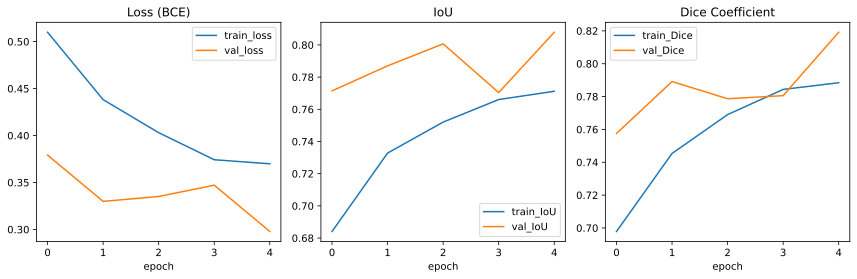

In [77]:
show_stats(num_epochs, history_train_loss, history_val_loss, history_train_iou, history_val_iou, history_train_dice, history_val_dice, 'BCE')

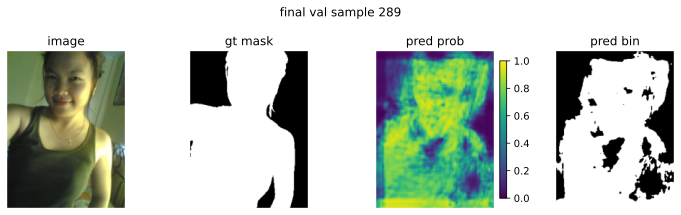

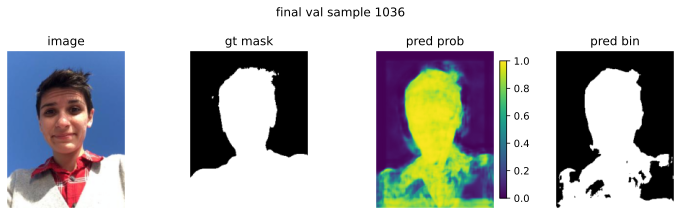

In [76]:
model.eval()
with torch.no_grad():
    sample_logits = model(val_vis_imgs.to(device))

for i in range(val_vis_imgs.shape[0]):
    fig = make_segmentation_figure(
        val_vis_imgs[i],
        val_vis_msks[i],
        sample_logits[i],
        title=f'final val sample {val_vis_indices[i]}',
        threshold=0.5
    )
    plt.show()
    plt.close(fig)

In [79]:
test_data_loader = DataLoader(test_dataset, batch_size=8, num_workers=3,shuffle=False)

In [80]:
test_model = UNet(num_classes=1, num_blocks=3).to(device)

state_dict = torch.load('/kaggle/working/best_model_bce.pth', map_location=device)
test_model.load_state_dict(state_dict)

test_model.eval()

test_criterion = nn.BCEWithLogitsLoss(reduction='mean')

test_running_loss = 0
test_running_iou = 0
test_running_dice = 0
num_batches = 0

with torch.no_grad():
    for imgs, msks in test_data_loader:
        imgs = imgs.to(device)
        msks = msks.to(device)

        logits = test_model(imgs)

        loss_val = test_criterion(logits, msks)

        iou_val = metric_iou(logits, msks)
        dice_val = dice_coefficient_from_logits(logits, msks)

        test_running_loss += loss_val.item()
        test_running_iou  += iou_val.item()
        test_running_dice += dice_val.item()
        num_batches += 1

test_loss = test_running_loss / num_batches
test_iou  = test_running_iou  / num_batches
test_dice = test_running_dice / num_batches

print('Test metrics')
print(f'test_loss (BCE): {test_loss:.4f}')
print(f'test_IoU: {test_iou:.4f}')
print(f'test_Dice: {test_dice:.4f}')


Test metrics
test_loss (BCE): 0.2963
test_IoU: 0.8166
test_Dice: 0.8239


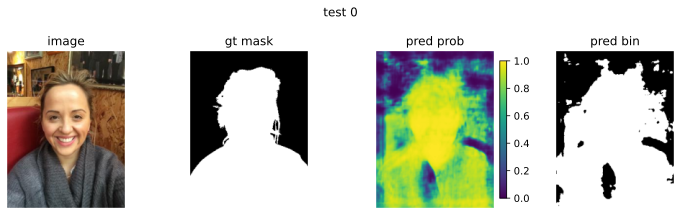

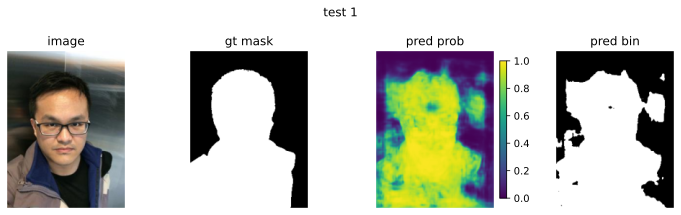

In [82]:
test_model.eval()
with torch.no_grad():
    test_logits_vis = test_model(test_vis_imgs)

for i in range(test_vis_imgs.shape[0]):
    fig = make_segmentation_figure(
        test_vis_imgs[i],
        test_vis_msks[i],
        test_logits_vis[i],
        title=f'test {test_vis_indices[i]}',
        threshold=0.5
    )
    plt.show()
    plt.close(fig)

### Только dice loss

In [92]:
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
model = UNet(num_classes=1, num_blocks=3).to(device)

criterion = DiceLoss(with_logits=True, reduction='mean')
metric_iou = IoUScore(threshold=0, reduction='mean')
optimizer = torch.optim.Adam(model.parameters(), lr=1e-4)

writer = SummaryWriter(log_dir='./runs/dice_v0')

hparams_dict = {
    'loss_type': 'DiceLoss',
    'lr': 1e-4,
    'batch_size': train_data_loader.batch_size,
    'optimizer': 'Adam',
    'num_blocks_unet': 4
}
writer.add_hparams(hparam_dict=hparams_dict, metric_dict={})

dummy_input = torch.randn(1, 3, train_vis_imgs.shape[2], train_vis_imgs.shape[3]).to(device)
writer.add_graph(model, dummy_input)

In [93]:
activation_storage = {}
gradient_storage = {}

model.encoder.blocks[0].register_forward_hook(make_forward_hook('enc_block0'))
model.encoder.blocks[-1].register_forward_hook(make_forward_hook('enc_block_last'))

In [94]:
num_epochs = 5
best_val_iou = -1

history_train_loss = []
history_val_loss = []
history_train_iou = []
history_val_iou = []
history_train_dice = []
history_val_dice = []

for epoch in range(num_epochs):
    print(f'epoch {epoch + 1}/{num_epochs}')

    train_loss, train_iou, train_dice = train_one_epoch(
        model, train_data_loader, optimizer, criterion, metric_iou, writer, epoch, device
    )

    val_loss, val_iou, val_dice = evaluate(
        model, val_data_loader, criterion, metric_iou, writer, epoch, device
    )

    history_train_loss.append(train_loss)
    history_val_loss.append(val_loss)
    history_train_iou.append(train_iou)
    history_val_iou.append(val_iou)
    history_train_dice.append(train_dice)
    history_val_dice.append(val_dice)

    model.eval()
    with torch.no_grad():
        train_logits_vis = model(train_vis_imgs.to(device))
        val_logits_vis = model(val_vis_imgs.to(device))
    
    for i in range(train_vis_imgs.shape[0]):
        fig = make_segmentation_figure(
            train_vis_imgs[i],
            train_vis_msks[i],
            train_logits_vis[i],
            title=f'train idx={train_vis_indices[i]} epoch={epoch} IoU={metric_iou(train_logits_vis[i:i+1], train_vis_msks[i:i+1]).item():.3f}',
            threshold=0.5
        )
        writer.add_figure(f'viz/train_sample_{i}', fig, global_step=epoch)
        plt.close(fig)
    
    for i in range(val_vis_imgs.shape[0]):
        fig = make_segmentation_figure(
            val_vis_imgs[i],
            val_vis_msks[i],
            val_logits_vis[i],
            title=f'val idx={val_vis_indices[i]} epoch={epoch} IoU={metric_iou(val_logits_vis[i:i+1], val_vis_msks[i:i+1]).item():.3f}',
            threshold=0.5
        )
        writer.add_figure(f'viz/val_sample_{i}', fig, global_step=epoch)
        plt.close(fig)
    
    if val_iou > best_val_iou:
        best_val_iou = val_iou
        torch.save(model.state_dict(), 'best_model_dice.pth')
        print('best model updated')

writer.close()


epoch 1/5
best model updated
epoch 2/5
best model updated
epoch 3/5
best model updated
epoch 4/5
best model updated
epoch 5/5
best model updated


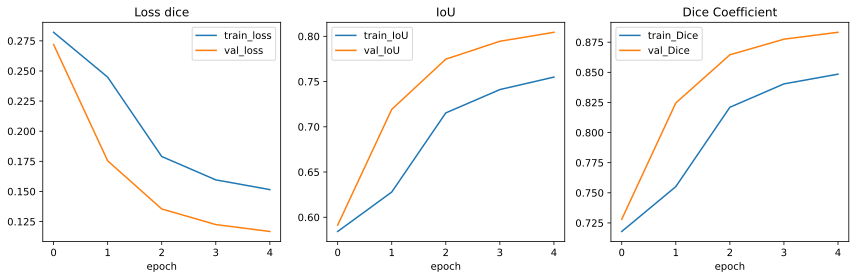

In [101]:
show_stats(num_epochs, history_train_loss, history_val_loss, history_train_iou, history_val_iou, history_train_dice, history_val_dice, 'dice')

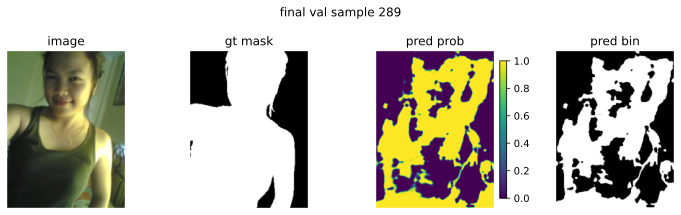

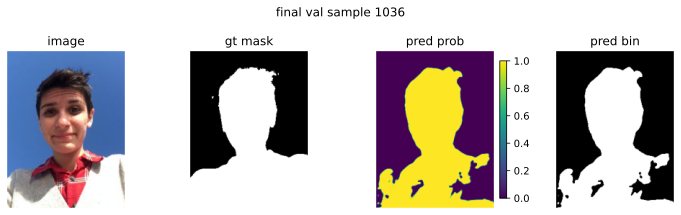

In [105]:
model.eval()
with torch.no_grad():
    sample_logits = model(val_vis_imgs.to(device))

for i in range(val_vis_imgs.shape[0]):
    fig = make_segmentation_figure(
        val_vis_imgs[i],
        val_vis_msks[i],
        sample_logits[i],
        title=f'final val sample {val_vis_indices[i]}',
        threshold=0.5
    )
    plt.show()
    plt.close(fig)

In [106]:
test_model = UNet(num_classes=1, num_blocks=3).to(device)

state_dict = torch.load('/kaggle/working/best_model_dice.pth', map_location=device)
test_model.load_state_dict(state_dict)

test_model.eval()

test_criterion = nn.BCEWithLogitsLoss(reduction='mean')

test_running_loss = 0
test_running_iou = 0
test_running_dice = 0
num_batches = 0

with torch.no_grad():
    for imgs, msks in test_data_loader:
        imgs = imgs.to(device)
        msks = msks.to(device)

        logits = test_model(imgs)

        loss_val = test_criterion(logits, msks)

        iou_val = metric_iou(logits, msks)
        dice_val = dice_coefficient_from_logits(logits, msks)

        test_running_loss += loss_val.item()
        test_running_iou  += iou_val.item()
        test_running_dice += dice_val.item()
        num_batches += 1

test_loss = test_running_loss / num_batches
test_iou  = test_running_iou  / num_batches
test_dice = test_running_dice / num_batches

print('Test metrics')
print(f'test_loss (Dice): {test_loss:.4f}')
print(f'test_IoU: {test_iou:.4f}')
print(f'test_Dice: {test_dice:.4f}')


Test metrics
test_loss (Dice): 2.1893
test_IoU: 0.8073
test_Dice: 0.8874


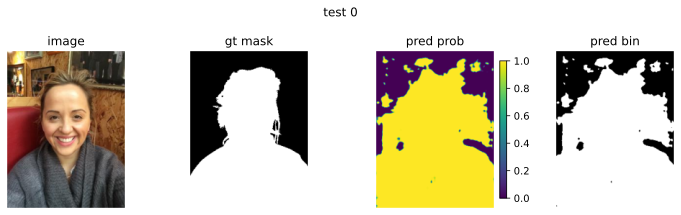

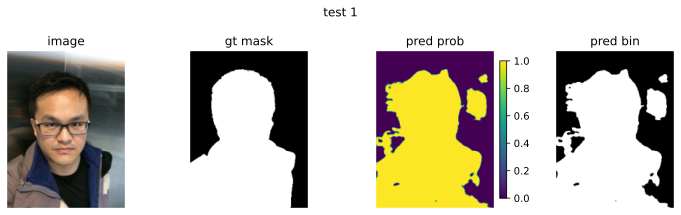

In [107]:
test_model.eval()
with torch.no_grad():
    test_logits_vis = test_model(test_vis_imgs)

for i in range(test_vis_imgs.shape[0]):
    fig = make_segmentation_figure(
        test_vis_imgs[i],
        test_vis_msks[i],
        test_logits_vis[i],
        title=f'test {test_vis_indices[i]}',
        threshold=0.5
    )
    plt.show()
    plt.close(fig)

In [108]:
class CombinedBCEDiceLoss(nn.Module):
    def __init__(self, alpha=0.5, beta=0.5):
        super().__init__()
        
        self.alpha = alpha
        self.beta = beta
        self.bce = nn.BCEWithLogitsLoss(reduction='mean')
        self.dice = DiceLoss(with_logits=True, reduction='mean')

    def forward(self, logits, target):
        loss_bce = self.bce(logits, target)
        loss_dice = self.dice(logits, target)
        
        return self.alpha * loss_bce + self.beta * loss_dice, loss_bce, loss_dice

In [111]:
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
model = UNet(num_classes=1, num_blocks=3).to(device)

criterion = CombinedBCEDiceLoss(alpha=0.5, beta=0.5)
metric_iou = IoUScore(threshold=0, reduction='mean')
optimizer = torch.optim.Adam(model.parameters(), lr=1e-4)

writer = SummaryWriter(log_dir='./runs/combined_v0')

hparams_dict = {
    'loss_type': 'CombinedBCEDiceLoss',
    'lr': 1e-4,
    'batch_size': train_data_loader.batch_size,
    'optimizer': 'Adam',
    'num_blocks_unet': 4
}
writer.add_hparams(hparam_dict=hparams_dict, metric_dict={})

dummy_input = torch.randn(1, 3, train_vis_imgs.shape[2], train_vis_imgs.shape[3]).to(device)
writer.add_graph(model, dummy_input)

In [112]:
activation_storage = {}
gradient_storage = {}

def make_forward_hook(name):
    def hook(module, inp, out):
        activation_storage[name] = out.detach().cpu()
    return hook

model.encoder.blocks[0].register_forward_hook(make_forward_hook('enc_block0'))
model.encoder.blocks[-1].register_forward_hook(make_forward_hook('enc_block_last'))

In [ ]:
@torch.no_grad()
def evaluate_combined(model, loader, criterion, metric_iou, writer, epoch, device):
    model.eval()
    
    running_loss_total = 0
    running_loss_bce = 0
    running_loss_dice = 0
    running_iou = 0
    running_dice_coef = 0
    num_batches = 0

    for imgs, msks in loader:
        imgs = imgs.to(device)
        msks = msks.to(device)

        logits = model(imgs)

        loss_total, loss_bce, loss_dice = criterion(logits, msks)

        iou_val = metric_iou(logits, msks)
        dice_val = dice_coefficient_from_logits(logits, msks)

        running_loss_total += loss_total.item()
        running_loss_bce += loss_bce.item()
        running_loss_dice += loss_dice.item()
        running_iou += iou_val.item()
        running_dice_coef += dice_val.item()
        num_batches += 1

    epoch_loss_total = running_loss_total / num_batches
    epoch_loss_bce = running_loss_bce / num_batches
    epoch_loss_dice = running_loss_dice / num_batches
    epoch_iou = running_iou / num_batches
    epoch_dice_coef = running_dice_coef / num_batches

    writer.add_scalar('val/loss_total_epoch', epoch_loss_total, epoch)
    writer.add_scalar('val/loss_bce_epoch', epoch_loss_bce, epoch)
    writer.add_scalar('val/loss_dice_epoch', epoch_loss_dice, epoch)
    writer.add_scalar('val/iou_epoch', epoch_iou, epoch)
    writer.add_scalar('val/dicecoef_epoch', epoch_dice_coef, epoch)

    return epoch_loss_total, epoch_loss_bce, epoch_loss_dice, epoch_iou, epoch_dice_coef

In [114]:
def train_one_epoch_combined(model, loader, optimizer, criterion, metric_iou, writer, epoch, device):
    model.train()
    running_loss_total = 0
    running_loss_bce = 0
    running_loss_dice = 0
    running_iou = 0
    running_dice_coef = 0
    num_batches = 0

    global_step_base = epoch * len(loader)

    for it, (imgs, msks) in enumerate(loader):
        imgs = imgs.to(device)
        msks = msks.to(device)

        optimizer.zero_grad()

        logits = model(imgs)

        loss_total, loss_bce, loss_dice = criterion(logits, msks)
        loss_total.backward()

        w_norm, g_norm = compute_norms(model)

        optimizer.step()

        with torch.no_grad():
            iou_val = metric_iou(logits, msks)
            dice_val = dice_coefficient_from_logits(logits, msks)

        running_loss_total += loss_total.item()
        running_loss_bce += loss_bce.item()
        running_loss_dice += loss_dice.item()
        running_iou += iou_val.item()
        running_dice_coef += dice_val.item()
        num_batches += 1

        step_id = global_step_base + it

        writer.add_scalar('train/loss_total_batch', loss_total.item(), step_id)
        writer.add_scalar('train/loss_bce_batch', loss_bce.item(), step_id)
        writer.add_scalar('train/loss_dice_batch', loss_dice.item(), step_id)
        writer.add_scalar('train/iou_batch', iou_val.item(), step_id)
        writer.add_scalar('train/dicecoef_batch', dice_val.item(), step_id)
        writer.add_scalar('train/weight_norm', w_norm, step_id)
        writer.add_scalar('train/grad_norm', g_norm, step_id)

        if it == 0:
            add_feature_maps_to_tensorboard(writer, step_id, activation_storage, gradient_storage)

    epoch_loss_total = running_loss_total / num_batches
    epoch_loss_bce = running_loss_bce / num_batches
    epoch_loss_dice = running_loss_dice / num_batches
    epoch_iou = running_iou / num_batches
    epoch_dice_coef = running_dice_coef / num_batches

    writer.add_scalar('train/loss_total_epoch', epoch_loss_total, epoch)
    writer.add_scalar('train/loss_bce_epoch', epoch_loss_bce, epoch)
    writer.add_scalar('train/loss_dice_epoch', epoch_loss_dice, epoch)
    writer.add_scalar('train/iou_epoch', epoch_iou, epoch)
    writer.add_scalar('train/dicecoef_epoch', epoch_dice_coef, epoch)

    return epoch_loss_total, epoch_loss_bce, epoch_loss_dice, epoch_iou, epoch_dice_coef


In [115]:
num_epochs = 5
best_val_iou = -1.0

history_train_total = []
history_val_total = []
history_train_bce = []
history_val_bce = []
history_train_dice = []
history_val_dice = []
history_train_iou = []
history_val_iou = []
history_train_dicecoef = []
history_val_dicecoef = []

for epoch in range(num_epochs):
    print(f'epoch {epoch + 1}/{num_epochs}')

    (train_total, train_bce, train_dice_l, train_iou, train_dicecoef) = train_one_epoch_combined(
        model, train_data_loader, optimizer, criterion, metric_iou, writer, epoch, device
    )

    (val_total, val_bce, val_dice_l, val_iou, val_dicecoef) = evaluate_combined(
        model, val_data_loader, criterion, metric_iou, writer, epoch, device
    )

    history_train_total.append(train_total)
    history_val_total.append(val_total)
    history_train_bce.append(train_bce)
    history_val_bce.append(val_bce)
    history_train_dice.append(train_dice_l)
    history_val_dice.append(val_dice_l)
    history_train_iou.append(train_iou)
    history_val_iou.append(val_iou)

    model.eval()
    with torch.no_grad():
        train_logits_vis = model(train_vis_imgs.to(device))
        val_logits_vis = model(val_vis_imgs.to(device))

    for i in range(train_vis_imgs.shape[0]):
        fig = make_segmentation_figure(
            train_vis_imgs[i],
            train_vis_msks[i],
            train_logits_vis[i],
            title=f'train idx={train_vis_indices[i]} epoch={epoch} IoU={metric_iou(train_logits_vis[i:i+1], train_vis_msks[i:i+1]).item():.3f}',
            threshold=0.5
        )
        writer.add_figure(f'viz/train_sample_{i}', fig, global_step=epoch)
        plt.close(fig)

    for i in range(val_vis_imgs.shape[0]):
        fig = make_segmentation_figure(
            val_vis_imgs[i],
            val_vis_msks[i],
            val_logits_vis[i],
            title=f'val idx={val_vis_indices[i]} epoch={epoch} IoU={metric_iou(val_logits_vis[i:i+1], val_vis_msks[i:i+1]).item():.3f}',
            threshold=0.5
        )
        writer.add_figure(f'viz/val_sample_{i}', fig, global_step=epoch)
        plt.close(fig)

    log_weight_histograms(writer, model, epoch)

    history_train_dicecoef.append(train_dicecoef)
    history_val_dicecoef.append(val_dicecoef)

    if val_iou > best_val_iou:
        best_val_iou = val_iou
        torch.save(model.state_dict(), 'best_model_combined.pth')
        print('best model updated')

writer.close()


epoch 1/5
best model updated
epoch 2/5
best model updated
epoch 3/5
best model updated
epoch 4/5
best model updated
epoch 5/5


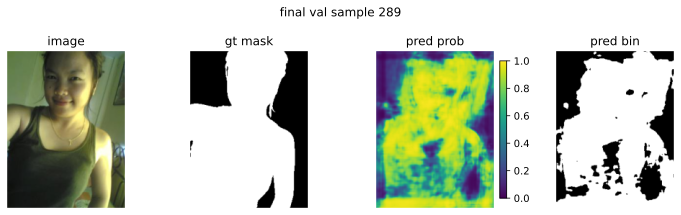

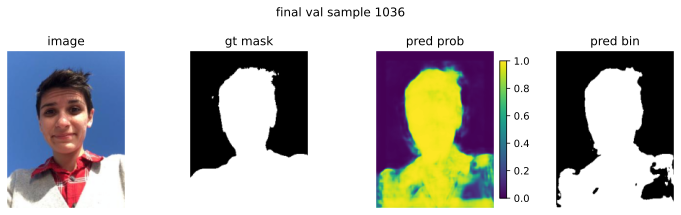

In [119]:
model.eval()
with torch.no_grad():
    sample_logits = model(val_vis_imgs.to(device))

for i in range(val_vis_imgs.shape[0]):
    fig = make_segmentation_figure(
        val_vis_imgs[i],
        val_vis_msks[i],
        sample_logits[i],
        title=f'final val sample {val_vis_indices[i]}',
        threshold=0.5
    )
    plt.show()
    plt.close(fig)

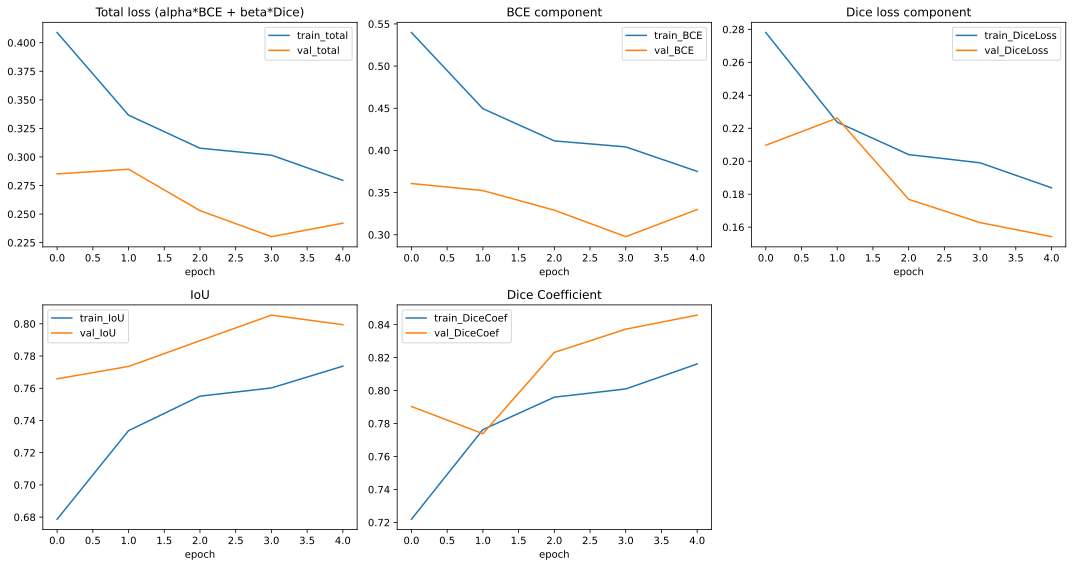

In [116]:
epochs_range = range(num_epochs)

plt.figure(figsize=(15,8))

plt.subplot(2,3,1)
plt.plot(epochs_range, history_train_total, label='train_total')
plt.plot(epochs_range, history_val_total, label='val_total')
plt.title('Total loss (alpha*BCE + beta*Dice)')
plt.xlabel('epoch')
plt.legend()

plt.subplot(2,3,2)
plt.plot(epochs_range, history_train_bce, label='train_BCE')
plt.plot(epochs_range, history_val_bce, label='val_BCE')
plt.title('BCE component')
plt.xlabel('epoch')
plt.legend()

plt.subplot(2,3,3)
plt.plot(epochs_range, history_train_dice, label='train_DiceLoss')
plt.plot(epochs_range, history_val_dice, label='val_DiceLoss')
plt.title('Dice loss component')
plt.xlabel('epoch')
plt.legend()

plt.subplot(2,3,4)
plt.plot(epochs_range, history_train_iou, label='train_IoU')
plt.plot(epochs_range, history_val_iou, label='val_IoU')
plt.title('IoU')
plt.xlabel('epoch')
plt.legend()

plt.subplot(2,3,5)
plt.plot(epochs_range, history_train_dicecoef, label='train_DiceCoef')
plt.plot(epochs_range, history_val_dicecoef, label='val_DiceCoef')
plt.title('Dice Coefficient')
plt.xlabel('epoch')
plt.legend()

plt.tight_layout()
plt.show()

In [117]:
test_model = UNet(num_classes=1, num_blocks=3).to(device)
state_dict = torch.load('/kaggle/working/best_model_combined.pth', map_location=device)
test_model.load_state_dict(state_dict)
test_model.eval()

test_criterion = CombinedBCEDiceLoss(alpha=0.5, beta=0.5)

test_running_total = 0
test_running_bce = 0
test_running_dice_l = 0
test_running_iou = 0
test_running_dicecoef = 0
num_batches = 0

with torch.no_grad():
    for imgs, msks in test_data_loader:
        imgs = imgs.to(device)
        msks = msks.to(device)

        logits = test_model(imgs)

        loss_total, loss_bce, loss_dice_l = test_criterion(logits, msks)
        iou_val = metric_iou(logits, msks)
        dice_val = dice_coefficient_from_logits(logits, msks)

        test_running_total += loss_total.item()
        test_running_bce += loss_bce.item()
        test_running_dice_l += loss_dice_l.item()
        test_running_iou += iou_val.item()
        test_running_dicecoef += dice_val.item()
        num_batches += 1

test_total = test_running_total / num_batches
test_bce = test_running_bce / num_batches
test_dice_l = test_running_dice_l / num_batches
test_iou = test_running_iou / num_batches
test_dicecoef = test_running_dicecoef / num_batches

print('Test metrics')
print(f'test_total_loss (alpha*BCE+beta*Dice): {test_total:.4f}')
print(f'test_bce_component: {test_bce:.4f}')
print(f'test_dice_component: {test_dice_l:.4f}')
print(f'test_IoU: {test_iou:.4f}')
print(f'test_DiceCoef: {test_dicecoef:.4f}')

Test metrics
test_total_loss (alpha*BCE+beta*Dice): 0.2323
test_bce_component: 0.3031
test_dice_component: 0.1615
test_IoU: 0.8074
test_DiceCoef: 0.8385


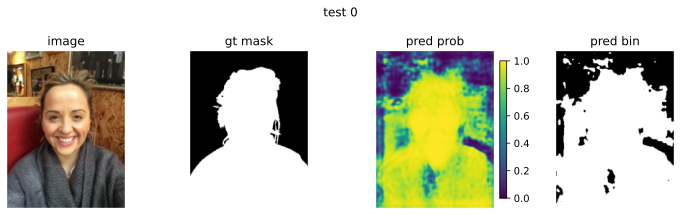

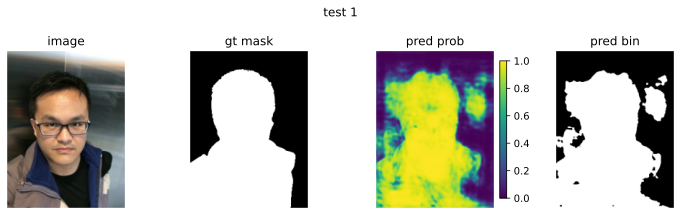

In [118]:
test_model.eval()
with torch.no_grad():
    test_logits_vis = test_model(test_vis_imgs)

for i in range(test_vis_imgs.shape[0]):
    fig = make_segmentation_figure(
        test_vis_imgs[i],
        test_vis_msks[i],
        test_logits_vis[i],
        title=f'test {test_vis_indices[i]}',
        threshold=0.5
    )
    plt.show()
    plt.close(fig)

Как видим, лучше всего по IoU себя продемонстрировала стратегия только с кросс-энтропией

## `LinkNet (2 балла)`

Реализуйте архитектуру [LinkNet](https://arxiv.org/pdf/1707.03718.pdf) с использованием энкодера, основанного на `VGG13`. Архитектура похожа на `Unet`, но вместо конкатенации слоёв используются skip-connections (сложения). Для реализации достаточно переписать структуру декодировщика из предыдущего пункта.

*Подсказка:* так как конкатенации слоёв заменили на skip-connections, то ожидается, что число параметров стало меньше.

**Обучите сеть и проведите анализ согласно предыдущему пункту. Сравните LinkNet и U-Net по качеству и скорости работы. Сделайте выводы.**

In [ ]:
# your code here

## `Теоретические вопросы (1 балл)`

### `Вопрос 1`
* Сформулируйте два предположения о структуре входных данных, на которые опирается архитектура свёрточных сетей. 
* Какие преимущества дает использование сверток в случае, если эти предположения верные? 
* Приведите пример входных данных, когда эти предположения не выполняются.

- Первое - это локальная коррелированность признаков, то есть важная информация в данных кодируется локальными паттернами: значения соседних пикселей сильно связаны между собой и вместе образуют осмысленные фрагменты. Второе - это переносимость признаков/инвариантность к сдвигу, что демонстрируется тем, что один и тот же признак может встречаться в разных местах входа, и его визуальный вид не зависит от абсолютной позиции.
- Уменьшение числа параметров: вместо того, чтобы учить отдельный набор весов для каждой позиции в изображении, модель учит один маленький фильтр и применяет его ко всем позициям; устойчивость к сдвигам объектов: если объект в кадре чуть сместился, свертка все равно его узнает, потому что тот же фильтр сканирует всю область; масштабируемость на большие входы.
- На графах: случайная структура связей, нет регулярной сетки и фиксированных локальных окрестностей.

### `Вопрос 2`
Пусть дано множество 1-D входов ${x^{(i)} \in \mathbb{R}^{100}}$. 

Рассмотрим полносвязный слой ${f(\cdot)}$, заданный как ${f(x^{(i)}) = \sigma(Wx^{(i)})}$, где ${W}$ - матрица весов размерности ${1000\times 100}$ и ${\sigma(\cdot)}$ поэлементая функция активации. 

Рассмотрим также сверточный слой ${g(\cdot)}$ с десятью картами признаков: ${g(x^{(i)}) = \sigma([z_1, z_2,...,z_{10}])}$, где ${z_j = x^{(i)}\ast w_j}$ для некоторого ядра свертки ${w_j}$ с размером 3 и паддингом 1. Для ${f(\cdot)}$ и ${g(\cdot)}$ напишите: 

1. Размерность выходного пространства. 
2. Количество обучаемых параметров. 
3. Число операций при выполнении forward pass (при условии наивной реализации перемножения матриц и вычисления сверток).

*Ваш ответ в этой ячейке*

## `Бонус: постобработка изображений (1 балл)`

В предложенной задаче на фотографиях необходимо сегментировать только центральное изображения. Артефакты, которые появляются на краях изображения, можно удалять с помощью постобработки (например, с помощью модуля [skimage.morphology](https://scikit-image.org/docs/dev/api/skimage.morphology.html)).

Реализуйте какой-нибудь из методов постобработки, дающий прирост в качестве. Продемонстрируйте несколько изображений, на которых постобработка будет оказывать влияние на результат сегментации.

## `Бонус: существенное улучшение качества (2 балла)`

Придумайте какой-нибудь трюк, который существенно (с учётом бонусного пункта 1) повысит качество (которое должно быть и так достаточно высоко). Не разрешается использовать дополнительные данные или другие предобученные кодировщики кроме VGG13.

Если вы что-то попробовали, но качество не повысилось, всё равно оформите этот пункт, даже за неудачные попытки могут быть начислены баллы.

## `Бонус: обучение с использованием сторонних фреймворков (1 балл)`

Попробуйте обучить свою модель с использованием одного из следующих фреймворков: [catalyst](https://github.com/catalyst-team/catalyst), [pytorch-lightning](https://www.pytorchlightning.ai/), [ignite](https://github.com/pytorch/ignite).

## `Бонус: аугментации (0.5 балла)`

Воспользуйтесь сторонними библиотеками для аугментаций, например, [deepaugment](https://github.com/barisozmen/deepaugment) и [albumentations](https://albumentations.ai/) для улучшения качества модели.

## `Бонус: torch.compile (0.25 балла)`

Попробуйте установить [Pytorch 2.0](https://pytorch.org/get-started/pytorch-2.0/) и запустите обучение с использованием `torch.compile`. Тщательно сравните время с и без использованием компиляции.

*Замечание:* обязательно укажите конфигурацию системы (версия OS, модель CPU/GPU, объём RAM), на которой производилось обучение. В частности, приложите вывод команд:
```bash
! nvcc --version
! nvidia-smi
```